In [1]:
import sys
import warnings
from pathlib import Path

import logging
import os

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"          # sin mensajes informativos de MLflow
logging.getLogger("mlflow").setLevel(logging.WARNING)
logging.getLogger("alembic").setLevel(logging.WARNING)
# Permite importar el paquete `proyecto` sin instalarlo: el código vive en src/
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 06 · Optimización con seguimiento (tracking) — Random Forest

Buscar mejores hiperparámetros es probar muchas configuraciones. Sin registro, a la mitad ya no se sabe cuál era la
buena: por eso **cada ensayo queda guardado en MLflow** con sus parámetros, métricas y etiquetas, para poder
**comparar, reproducir y auditar**.

Los tres cuidados del curso:

1. **Se optimiza solo un finalista del torneo:** el **Random Forest** (notebook 05).
2. **El espacio de búsqueda es conocimiento, no azar**, y el **presupuesto de ensayos se fija antes**.
3. **La mejor puntuación de una búsqueda es optimista**: se **comprueba** en asociados que la búsqueda nunca vio.

Y los dos objetivos del equipo para esta etapa:

- **Evitar el sobreajuste al máximo.** Cada ensayo mide la **brecha** entre el desempeño en los datos con que se
  entrenó y en los que no vio. Un ensayo con brecha mayor que el tope fijado de antemano **no se puede elegir**.
- **Optimizar la identificación de la clase minoritaria** (quien radica). Se maximiza el **PR-AUC**, la métrica que
  mide qué tan arriba de la lista quedan quienes de verdad radican.

El código vive en `src/proyecto/models/tuning.py`, construido sobre el `tuning.py` del ejemplo del curso:

| Función | Qué hace |
|---|---|
| `rf_space`, `make_rf` | Espacio de búsqueda del bosque y el modelo con los parámetros de cada ensayo |
| `tune` | Estudio de Optuna con la restricción de brecha; cada ensayo, una ejecución anidada en MLflow; reanudable |
| `select_best`, `trials_table` | El mejor ensayo **admisible** y la tabla de todos los ensayos |
| `bootstrap_difference` | Diferencia de una métrica entre dos modelos con intervalo del 95 %, remuestreando asociados |

## 0. Conexión con el seguimiento

In [2]:
import json
import time

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

from proyecto.config import CONTACT_COST, ID_COL, PROCESSED_DIR, RANDOM_STATE, REPORTS_DIR, RETENTION_RATE, TARGET
from proyecto.data.split import make_folds, split_by_group
from proyecto.models.business import campaign_value, contact_by_expected_value
from proyecto.models.train import (TRAIN_SAMPLE, build_pipeline, candidates, contacts_for_recall, evaluate_folds,
                                   fold_metrics)
from proyecto.models.tuning import (GAP, N_TREES, bootstrap_difference, make_rf, select_best, trials_table, tune)
from proyecto.tracking.mlflow_utils import configure_mlflow, set_experiment
from proyecto.viz import (ALERT, CHURN, LIGHT, NEUTRAL, STAY, SUBTEXT, TEXT, decimal_axis, fmt_num, fmt_pct, set_style,
                          table, titled)

set_style()
pd.set_option("display.width", 170)

with warnings.catch_warnings(record=True) as caught:   # se muestra por qué se usó (o no) Databricks
    warnings.simplefilter("always")
    where = configure_mlflow()
for w in caught:
    print("Aviso:", w.message)
experiment = set_experiment("retiro-asociados-optimizacion")
print("MLflow:", where, "| experimento:", experiment)

2026/11/05 18:57:09 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/05 18:57:09 INFO mlflow.store.db.utils: Updating database tables


2026/11/05 18:57:17 INFO mlflow.tracking.fluent: Experiment with name 'retiro-asociados-optimizacion' does not exist. Creating a new experiment.


MLflow: local | experimento: retiro-asociados-optimizacion


> **Si dice `local`:** no hay conexión con Databricks (no existe `.env` con el perfil o el token). El notebook funciona
> igual y guarda todo en `mlflow_local.db`, en la raíz del repositorio (ignorado por Git). Para verlo en el navegador:
> `mlflow ui --backend-store-uri sqlite:///mlflow_local.db`. Cuando el equipo complete `.env`, el mismo código registra
> en Databricks sin cambiar nada.

## 1. Reservar asociados que la búsqueda no verá

Del conjunto de entrenamiento se separa el **25 % de los asociados** (semilla 7, como pide la guía), estratificado por
grupo igual que en el notebook 03. La búsqueda trabaja solo con el 75 %, con **3 pliegues por asociado** (como el
ejemplo del curso: cada ensayo cuesta tres ajustes del bosque). **La prueba final sigue cerrada.**

In [3]:
train = joblib.load(PROCESSED_DIR / "train.joblib")
columns = json.loads((REPORTS_DIR / "04_seleccion_variables.json").read_text(encoding="utf-8"))["columns"]

search, reserved = split_by_group(train, group_col=ID_COL, strat_col="stratum", test_size=0.25, seed=7)
assert set(search[ID_COL]).isdisjoint(reserved[ID_COL]), "hay asociados en los dos lados"
search_folds = make_folds(search, n_splits=3, seed=RANDOM_STATE)

split_summary = pd.DataFrame({
    "asociados": [len(search), len(reserved)],
    "tasa de radicación": [search[TARGET].mean(), reserved[TARGET].mean()],
    "para qué": ["búsqueda (3 pliegues)", "comprobación honesta: la búsqueda nunca lo ve"],
}, index=["búsqueda", "reservados"])
display(table(split_summary, pct_cols=["tasa de radicación"]))
print(f"Variables: {len(columns)} (las del notebook 04) · prueba (test.joblib) cerrada")

,asociados,tasa de radicación,para qué
búsqueda,116.443,"20,9 %",búsqueda (3 pliegues)
reservados,38.815,"20,9 %",comprobación honesta: la búsqueda nunca lo ve


Variables: 27 (las del notebook 04) · prueba (test.joblib) cerrada


## 2. El punto de partida: ¿cuánto sobreajusta el Random Forest del torneo?

El Random Forest del torneo usa los parámetros por defecto: árboles **sin límite de profundidad** y hojas de **un solo
asociado**. Medimos su PR-AUC y su AUC en la parte de ajuste de cada pliegue (lo que ya vio) y en la de validación (lo
que no vio). La diferencia es la **brecha de sobreajuste**. En la parte de ajuste se mide con una muestra fija de
30.000 asociados por pliegue, que basta para estimarla y cuesta mucho menos.

In [4]:
default_model = candidates(RANDOM_STATE)["Random Forest"]
start = time.perf_counter()
default_cv = evaluate_folds(build_pipeline(default_model, columns), search, search_folds, train_metrics=True)
print(f"Validación cruzada del Random Forest por defecto: {time.perf_counter() - start:.0f} s")
start_table = pd.DataFrame({
    "en lo que ya vio (ajuste)": [default_cv["PR-AUC (ajuste)"].mean(), default_cv["AUC (ajuste)"].mean()],
    "en lo que no vio (validación)": [default_cv["PR-AUC"].mean(), default_cv["AUC"].mean()],
    "brecha": [default_cv[GAP].mean(), default_cv["brecha AUC"].mean()],
    "± validación": [default_cv["PR-AUC"].std(), default_cv["AUC"].std()],
}, index=["PR-AUC", "AUC"])
display(table(start_table, decimals=4))

Validación cruzada del Random Forest por defecto: 32 s


,en lo que ya vio (ajuste),en lo que no vio (validación),brecha,± validación
PR-AUC,"1,0000","0,6957","0,3043","0,0042"
AUC,"1,0000","0,8928","0,1072","0,0025"


**Lectura del punto de partida.**

- **El Random Forest del torneo memoriza el entrenamiento:** en lo que ya vio tiene PR-AUC y AUC de 1,0000, es decir,
  "acierta" a todos; en lo que no vio, 0,6957 y 0,8928. La brecha de PR-AUC es de **0,30**. Sus árboles sin límite crecen
  hasta aislar a cada asociado de entrenamiento.
- **No es un mal modelo:** fue el mejor del torneo y su desempeño en validación es real. Pero buena parte de lo que
  aprendió es la historia particular de cada asociado. Un modelo así es más frágil cuando cambia la población (y la
  población de la cooperativa cambia: nuevas cohortes, nuevos productos) y más pesado de llevar a la app.
- **El objetivo de la búsqueda** queda claro: conservar un PR-AUC cercano a 0,696 con una brecha de 0,10 o menos.

## 3. Diseño de la búsqueda (escrito antes de buscar)

**Qué se optimiza: el PR-AUC** de la validación cruzada. Es el área bajo la curva precisión–recall de la clase
minoritaria: mide si quienes van a radicar quedan **arriba de la lista**, sin depender de ningún umbral. Es la forma
directa de "identificar mejor la clase minoritaria". El recall por sí solo no sirve como objetivo: se maximiza
marcando a todos (lo advierte el ejemplo del curso). Como controles se registran el beneficio neto, el Brier, el AUC y
el recall en cada ensayo.

**La restricción contra el sobreajuste:** un ensayo es **admisible** solo si su **brecha de PR-AUC** (ajuste −
validación) **es de 0,10 o menos**, un tercio de la del modelo por defecto. Una brecha de cero es imposible (todo modelo
conoce mejor lo que vio); 0,10 obliga a que el bosque aprenda reglas generales y no la historia de cada asociado. El
muestreador de Optuna recibe la restricción y aprende a evitar las zonas no admisibles; el mejor ensayo se elige **solo
entre los admisibles**.

**El espacio de búsqueda** (los parámetros que controlan cuánto memoriza cada árbol):

| Parámetro | Rango | Por qué |
|---|---|---|
| `max_depth` | 6 a 24 | Por defecto no tiene límite: el árbol crece hasta aislar a cada asociado |
| `min_samples_leaf` | 1 a 100 (escala log) | Hojas con más asociados = reglas más generales; la escala log explora igual 1–10 que 10–100 |
| `max_features` | 0,15 a 0,80 | Menos variables por corte = árboles más distintos entre sí, menos varianza |
| `max_samples` | 0,50 a 1,00 | Cada árbol ve solo una parte de los asociados: más diversidad y menos memoria |
| `n_estimators` | **fijo en 200** | Más árboles no sobreajustan, solo cuestan: se afina la **forma**, no la cantidad (como el ejemplo del curso) |

**Presupuesto: 20 ensayos**, dentro de lo que recomienda la guía (12–20). Cada ensayo son 3 ajustes de un bosque de
200 árboles sobre unos 77.600 asociados.

**¿Y el desbalance?** El torneo no lo trató para comparar modelos en igualdad. Aquí, con el modelo ya elegido, se
aborda de forma explícita: `class_weight` **no entra en la búsqueda**, porque mueve el punto de operación sin mejorar
el ordenamiento y distorsiona las probabilidades que usa la regla de valor esperado. Para no descartarlo por intuición,
**se mide en la comprobación honesta** (sección 5).

**Regla de decisión final (escrita antes de mirar):** se adoptan los parámetros optimizados si, en los asociados
reservados, (a) **todo** el intervalo del 95 % de la diferencia de PR-AUC (optimizado − partida) está por encima de cero,
o (b) el intervalo cruza el cero (no se distinguen en PR-AUC) **pero** la brecha de sobreajuste es menor y el beneficio
neto no empeora (su intervalo no queda entero por debajo de cero). Con igual capacidad, se prefiere el modelo que menos
memoriza. Si no se cumple ninguna, se quedan los de partida.

## 4. La búsqueda (un ensayo = una ejecución registrada en MLflow)

Optuna usa un muestreador bayesiano (TPE): aprende qué zonas del espacio dieron mejor PR-AUC y explora más ahí. Cada
ensayo es una **ejecución anidada** dentro de una ejecución madre en MLflow. El estudio se guarda en
`data/processed/06_optuna_rf.db`: si la ejecución se corta, al volver a correr **se reanuda** sin repetir ensayos ni
duplicar el registro.

In [5]:
N_TRIALS = 20
MAX_GAP = 0.10
storage = PROCESSED_DIR / "06_optuna_rf.db"

start = time.perf_counter()
study = tune("Random Forest", search, columns, search_folds, n_trials=N_TRIALS, metric="PR-AUC", max_gap=MAX_GAP,
             storage=str(storage), study_name="retiro-asociados-random-forest-pr-auc")
trials = trials_table(study, max_gap=MAX_GAP)
best = select_best(study, max_gap=MAX_GAP)
print(f"{len(trials)} ensayos en {(time.perf_counter() - start) / 60:.0f} min · admisibles: {int(trials['admisible'].sum())}")
print(f"Mejor ensayo admisible: n.º {best.number} · PR-AUC {fmt_num(best.value, 4)} · brecha {fmt_num(best.user_attrs[GAP], 4)}")
print("Parámetros:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in best.params.items()})

20 ensayos en 22 min · admisibles: 14
Mejor ensayo admisible: n.º 19 · PR-AUC 0,6966 · brecha 0,0881
Parámetros: {'max_depth': 14, 'min_samples_leaf': 15, 'max_features': 0.269, 'max_samples': 0.926}


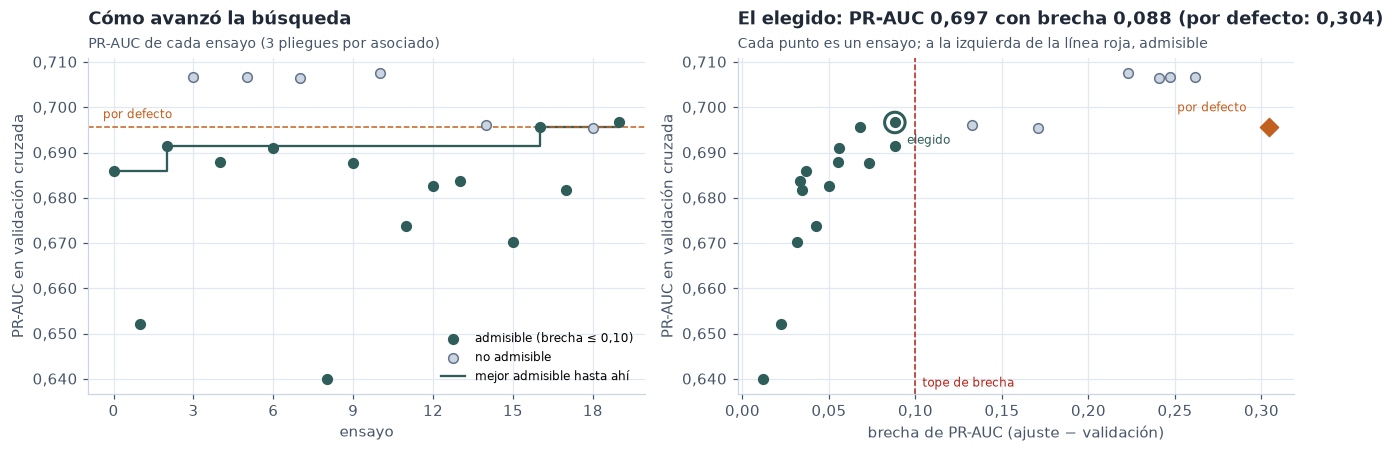

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ok = trials["admisible"]
ax.scatter(trials.index[ok], trials.loc[ok, "PR-AUC"], color=STAY, s=40, label="admisible (brecha ≤ 0,10)", zorder=3)
ax.scatter(trials.index[~ok], trials.loc[~ok, "PR-AUC"], color=LIGHT, edgecolor=NEUTRAL, s=40, label="no admisible", zorder=3)
best_so_far = trials["PR-AUC"].where(ok).cummax().ffill()
ax.step(trials.index, best_so_far, where="post", color=STAY, lw=1.5, label="mejor admisible hasta ahí")
ax.axhline(default_cv["PR-AUC"].mean(), color=CHURN, ls="--", lw=1)
ax.text(-0.4, default_cv["PR-AUC"].mean() + 0.0012, "por defecto", color=CHURN, fontsize=8, ha="left", va="bottom")
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("ensayo"); ax.set_ylabel("PR-AUC en validación cruzada"); ax.legend(loc="lower right", fontsize=8)
decimal_axis(ax, "y", 3)
titled(ax, "Cómo avanzó la búsqueda", "PR-AUC de cada ensayo (3 pliegues por asociado)")

ax = axes[1]
ax.scatter(trials.loc[ok, GAP], trials.loc[ok, "PR-AUC"], color=STAY, s=40, zorder=3)
ax.scatter(trials.loc[~ok, GAP], trials.loc[~ok, "PR-AUC"], color=LIGHT, edgecolor=NEUTRAL, s=40, zorder=3)
ax.scatter([default_cv[GAP].mean()], [default_cv["PR-AUC"].mean()], color=CHURN, s=70, marker="D", zorder=4)
ax.annotate("por defecto", (default_cv[GAP].mean(), default_cv["PR-AUC"].mean()), xytext=(-60, 10),
            textcoords="offset points", fontsize=8, color=CHURN)
ax.scatter([best.user_attrs[GAP]], [best.value], s=180, facecolor="none", edgecolor=STAY, lw=2, zorder=5)
ax.annotate("elegido", (best.user_attrs[GAP], best.value), xytext=(8, -14), textcoords="offset points", fontsize=8, color=STAY)
ax.axvline(MAX_GAP, color=ALERT, ls="--", lw=1)
ax.text(MAX_GAP + 0.004, ax.get_ylim()[0] + 0.001, "tope de brecha", color=ALERT, fontsize=8, va="bottom")
ax.set_xlabel("brecha de PR-AUC (ajuste − validación)"); ax.set_ylabel("PR-AUC en validación cruzada")
decimal_axis(ax, "y", 3); decimal_axis(ax, "x", 2)
titled(ax, f"El elegido: PR-AUC {fmt_num(best.value, 3)} con brecha {fmt_num(best.user_attrs[GAP], 3)} "
           f"(por defecto: {fmt_num(default_cv[GAP].mean(), 3)})",
       "Cada punto es un ensayo; a la izquierda de la línea roja, admisible")
plt.tight_layout(); plt.show()

**Lectura de la búsqueda.**

- **14 de los 20 ensayos fueron admisibles.** Los cuatro con el PR-AUC más alto de toda la búsqueda (entre 0,7065 y
  0,7075) **no lo son**: tienen hojas de 1 a 5 asociados y brechas de 0,22 a 0,26. **Los últimos 0,01 de PR-AUC se pagan
  memorizando**: es el sobreajuste que el equipo quiere evitar, y la restricción lo deja fuera.
- **El mejor ensayo admisible (n.º 19) logra un PR-AUC de 0,6966 con una brecha de 0,0881.** Es prácticamente el mismo
  PR-AUC del modelo por defecto (0,6957), con menos de un tercio de su brecha (0,3043).
- **El gráfico de la derecha muestra el precio de ir más allá:** con brechas por debajo de 0,05 el PR-AUC cae (los siete
  ensayos con brecha menor a 0,05 quedan entre 0,640 y 0,686). Hay un punto de equilibrio, y la búsqueda lo encontró.
- **La mejor puntuación de una búsqueda es optimista** (se eligió el máximo entre 14 ensayos con ruido): por eso se
  comprueba en la sección 5, con asociados que la búsqueda nunca vio.

### ¿Qué parámetros importaron?

La importancia de cada parámetro (según Optuna) dice dónde vale la pena seguir buscando y dónde no. Abajo, los cinco
mejores ensayos admisibles.

In [7]:
importance = pd.Series(optuna.importance.get_param_importances(study), name="importancia").to_frame()
display(table(importance, decimals=3))
cols_show = ["max_depth", "min_samples_leaf", "max_features", "max_samples", "PR-AUC", GAP, "AUC", "Brier",
             "beneficio neto (por 1.000)", "segundos de ajuste"]
top5 = trials[trials["admisible"]].sort_values("PR-AUC", ascending=False)[cols_show].head(5)
display(table(top5, decimals=4, col_decimals={"max_features": 3, "max_samples": 3, "beneficio neto (por 1.000)": 2,
                                              "segundos de ajuste": 1}))

,importancia
min_samples_leaf,"0,477"
max_features,"0,311"
max_depth,"0,205"
max_samples,"0,007"


,max_depth,min_samples_leaf,max_features,max_samples,PR-AUC,brecha PR-AUC,AUC,Brier,beneficio neto (por 1.000),segundos de ajuste
ensayo,,,,,,,,,,
19,14,15,"0,269","0,926","0,6966","0,0881","0,8931","0,1026","33,51","21,1"
16,19,33,"0,353","0,761","0,6957","0,0678","0,8925","0,1026","33,52","20,9"
2,17,21,"0,163","0,985","0,6915","0,0884","0,8911","0,1044","33,36","14,7"
6,14,32,"0,280","0,757","0,6911","0,0558","0,8908","0,1039","33,42","16,9"
4,11,8,"0,431","0,646","0,6879","0,0552","0,8897","0,1040","33,48","22,3"


**Lectura.**

- **`min_samples_leaf` es el parámetro que más pesa** (importancia 0,477), seguido de `max_features` (0,311) y
  `max_depth` (0,205). `max_samples` casi no importa (0,007). Tiene sentido: el tamaño mínimo de la hoja es justamente
  el freno a la memorización.
- **Los cinco mejores admisibles forman una meseta:** PR-AUC entre 0,688 y 0,697, con hojas de 8 a 33 asociados,
  profundidad de 11 a 19 y entre el 16 % y el 43 % de las variables por corte. Los dos primeros (ensayos 19 y 16) están
  separados por 0,001, menos que la variación entre pliegues (alrededor de 0,003): son equivalentes.
- **Configuración elegida (ensayo 19):** 200 árboles, profundidad máxima 14, hojas de al menos 15 asociados, 27 % de las
  variables por corte y 93 % de los asociados por árbol.

## 5. La comprobación honesta

Se entrenan con **todos los asociados de búsqueda** tres modelos y se evalúan en los **38.815 asociados reservados**,
que ninguno vio:

1. **Partida:** el Random Forest del torneo (parámetros por defecto).
2. **Optimizado:** los parámetros del mejor ensayo admisible.
3. **Optimizado + `class_weight="balanced_subsample"`:** la prueba explícita del tratamiento del desbalance.

Las diferencias llevan un intervalo del 95 % que remuestrea **asociados** (500 repeticiones).

In [8]:
y_search, y_res = search[TARGET].to_numpy(), reserved[TARGET].to_numpy()
value_res = reserved["saldo_aportes"].to_numpy()
X_search, X_res = search.drop(columns=[TARGET]), reserved.drop(columns=[TARGET])
fit_sample = np.random.default_rng(RANDOM_STATE).choice(len(search), TRAIN_SAMPLE, replace=False)

contenders = {
    "partida (por defecto)": candidates(RANDOM_STATE)["Random Forest"],
    "optimizado": make_rf(best.params),
    "optimizado + class_weight": make_rf(best.params).set_params(class_weight="balanced_subsample"),
}
proba, fitted, rows = {}, {}, []
for name, model in contenders.items():
    start = time.perf_counter()
    fitted[name] = build_pipeline(model, columns).fit(X_search, y_search)
    seconds = time.perf_counter() - start
    proba[name] = fitted[name].predict_proba(X_res)[:, 1]
    p_fit = fitted[name].predict_proba(X_search.iloc[fit_sample])[:, 1]
    metrics = fold_metrics(y_res, proba[name], value_res)
    effort = contacts_for_recall(y_res, proba[name], 0.75)
    rows.append({"modelo": name,
                 "PR-AUC (reservados)": metrics["PR-AUC"],
                 "PR-AUC (lo que vio)": average_precision_score(y_search[fit_sample], p_fit),
                 "brecha PR-AUC": average_precision_score(y_search[fit_sample], p_fit) - metrics["PR-AUC"],
                 "AUC (reservados)": metrics["AUC"], "Brier": metrics["Brier"],
                 "beneficio neto (por 1.000)": metrics["beneficio neto (por 1.000)"],
                 "recall (0,5)": metrics["recall"], "precisión (0,5)": metrics["precisión"],
                 "contactos para detectar el 75 %": effort["contactos"],
                 "segundos de ajuste": seconds})
check = pd.DataFrame(rows).set_index("modelo")
display(table(check, decimals=4, col_decimals={"beneficio neto (por 1.000)": 2, "segundos de ajuste": 1}))

,PR-AUC (reservados),PR-AUC (lo que vio),brecha PR-AUC,AUC (reservados),Brier,beneficio neto (por 1.000),"recall (0,5)","precisión (0,5)",contactos para detectar el 75 %,segundos de ajuste
modelo,,,,,,,,,,
partida (por defecto),"0,6993","1,0000","0,3007","0,8937","0,1010","33,44","0,5074","0,7395",10.567,"14,9"
optimizado,"0,6971","0,7707","0,0737","0,8932","0,1022","33,44","0,4778","0,7477",10.639,"35,3"
optimizado + class_weight,"0,6890","0,7475","0,0585","0,8916","0,1319","32,18","0,8209","0,5130",10.725,"38,1"


In [9]:
groups = reserved[ID_COL].to_numpy()

def pr_auc(rows, p):
    return average_precision_score(y_res[rows], p[rows])

def benefit(rows, p):
    contact = contact_by_expected_value(p[rows], value_res[rows], CONTACT_COST, RETENTION_RATE)
    return campaign_value(y_res[rows], contact, value_res[rows], CONTACT_COST, RETENTION_RATE)["beneficio_neto"] / len(rows) * 1000

def brier(rows, p):
    return np.mean((p[rows] - y_res[rows]) ** 2)

comparisons = [("optimizado", "partida (por defecto)"), ("optimizado + class_weight", "optimizado")]
ci_rows = []
for a, b in comparisons:
    for label, fn in [("PR-AUC", pr_auc), ("beneficio neto (por 1.000)", benefit), ("Brier", brier)]:
        diff, low, high = bootstrap_difference(fn, proba[a], proba[b], groups, n_boot=500)
        ci_rows.append({"comparación": f"{a} − {b}", "métrica": label, "diferencia": diff, "IC 95 % inferior": low,
                        "IC 95 % superior": high,
                        "lectura": "a favor de la primera" if (low > 0 if label != "Brier" else high < 0) else
                                   ("a favor de la segunda" if (high < 0 if label != "Brier" else low > 0) else "no se distinguen")})
ci = pd.DataFrame(ci_rows).set_index(["comparación", "métrica"])
display(table(ci, decimals=4))

In [10]:
pr = ci.loc[("optimizado − partida (por defecto)", "PR-AUC")]
money = ci.loc[("optimizado − partida (por defecto)", "beneficio neto (por 1.000)")]
gap_tuned, gap_default = check.loc["optimizado", "brecha PR-AUC"], check.loc["partida (por defecto)", "brecha PR-AUC"]
rule_a = pr["IC 95 % inferior"] > 0
rule_b = (pr["IC 95 % inferior"] <= 0 <= pr["IC 95 % superior"]) and gap_tuned < gap_default and money["IC 95 % superior"] >= 0
decision = "optimizados" if (rule_a or rule_b) else "de partida"
print(f"(a) ¿todo el intervalo de PR-AUC por encima de cero?  {rule_a}")
print(f"(b) ¿no se distinguen en PR-AUC, la brecha baja ({fmt_num(gap_default, 3)} → {fmt_num(gap_tuned, 3)}) "
      f"y el beneficio no empeora?  {rule_b}")
print(f"DECISIÓN: se usan los parámetros {decision.upper()}.")

(a) ¿todo el intervalo de PR-AUC por encima de cero?  False
(b) ¿no se distinguen en PR-AUC, la brecha baja (0,301 → 0,074) y el beneficio no empeora?  True
DECISIÓN: se usan los parámetros OPTIMIZADOS.


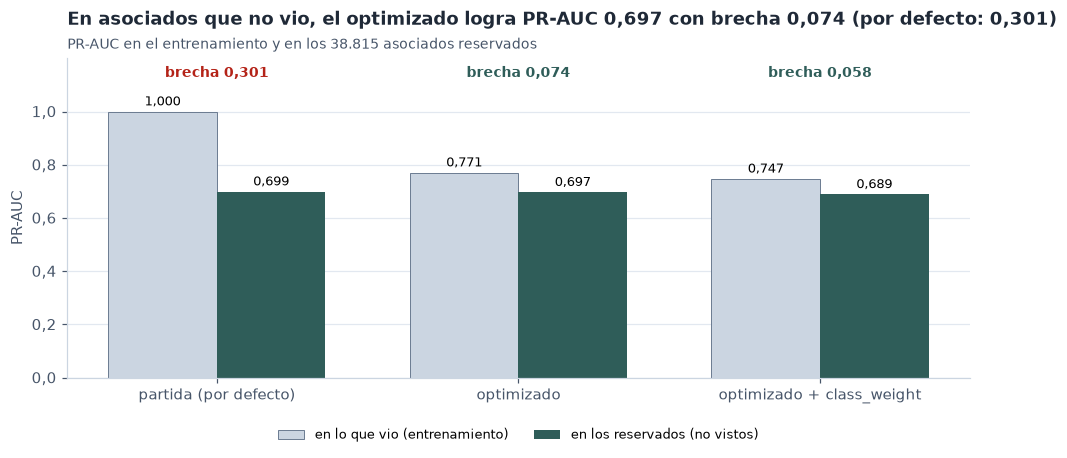

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.3))
names = list(check.index)
x = np.arange(len(names)); width = 0.36
seen = ax.bar(x - width / 2, check["PR-AUC (lo que vio)"], width, color=LIGHT, edgecolor=NEUTRAL, lw=0.6,
              label="en lo que vio (entrenamiento)")
unseen = ax.bar(x + width / 2, check["PR-AUC (reservados)"], width, color=STAY, label="en los reservados (no vistos)")
ax.bar_label(seen, labels=[fmt_num(v, 3) for v in check["PR-AUC (lo que vio)"]], padding=2, fontsize=8.5)
ax.bar_label(unseen, labels=[fmt_num(v, 3) for v in check["PR-AUC (reservados)"]], padding=2, fontsize=8.5)
for i, gap in enumerate(check["brecha PR-AUC"]):
    ax.text(i, 1.13, f"brecha {fmt_num(gap, 3)}", ha="center", fontsize=9, fontweight="bold",
            color=ALERT if gap > MAX_GAP else STAY)
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylim(0, 1.2); ax.set_ylabel("PR-AUC")
ax.set_yticks(np.arange(0, 1.01, 0.2))
decimal_axis(ax, "y", 1); ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8.5)
titled(ax, f"En asociados que no vio, el optimizado logra PR-AUC {fmt_num(check.loc['optimizado', 'PR-AUC (reservados)'], 3)} "
           f"con brecha {fmt_num(gap_tuned, 3)} (por defecto: {fmt_num(gap_default, 3)})",
       "PR-AUC en el entrenamiento y en los 38.815 asociados reservados")
plt.tight_layout(); plt.show()

**Lectura de la comprobación honesta.**

- **El sobreajuste bajó a la cuarta parte.** En los asociados reservados, la brecha del optimizado es de 0,074 frente a
  0,301 del modelo por defecto (gráfico). La búsqueda no lo había sobreestimado.
- **La identificación de quien radica se mantuvo.** PR-AUC 0,6971 frente a 0,6993: la diferencia (−0,0022) tiene un
  intervalo del 95 % de −0,0059 a +0,0014, que **cruza el cero**. No se distinguen. El AUC tampoco cambia (0,8932 frente a
  0,8937), y para detectar al 75 % de quienes radican hacen falta prácticamente los mismos contactos (10.639 frente a 10.567
  entre los 38.815 reservados).
- **El beneficio neto es el mismo:** 33,44 millones por cada 1.000 asociados en ambos (intervalo de −0,14 a +0,12).
- **Un costo pequeño en calibración:** el Brier del optimizado es 0,0012 mayor y esa diferencia **sí es real** (intervalo
  de +0,0007 a +0,0017). Las hojas más grandes suavizan las probabilidades. Es poco, pero la regla de valor esperado usa
  la probabilidad como número, así que **la calibración se revisa en el notebook 07**.
- **Aplicación de la regla escrita antes de mirar:** (a) no se cumple, porque no hay mejora demostrable de PR-AUC; (b) sí
  se cumple: no se distinguen en PR-AUC, la brecha baja y el beneficio no empeora. **Se adoptan los parámetros
  optimizados.**

**El tratamiento del desbalance, medido.** Con `class_weight="balanced_subsample"` el recall en el umbral 0,5 sube de 0,478
a 0,821, pero la precisión cae de 0,748 a 0,513: solo **mueve el punto de operación**. Y lo que importa empeora, todo con
intervalos que no tocan el cero: el PR-AUC baja 0,0081, el Brier sube 0,0297 (probabilidades mucho menos creíbles) y el
beneficio neto cae 1,26 millones por cada 1.000 asociados. **Se descarta, con evidencia.** Para encontrar a más asociados
que van a radicar, la herramienta correcta es el punto de operación (regla de valor esperado o umbral), que se fija en el
notebook 07 sin dañar las probabilidades.

## 6. Lo que quedó registrado en MLflow

Cada ensayo es una ejecución con sus parámetros, todas las métricas (con su desviación entre pliegues) y las etiquetas
`etapa`, `modelo`, `metrica_optimizada` y `admisible`. Los cinco mejores admisibles, consultados directamente en MLflow:

In [12]:
runs = mlflow.search_runs(
    experiment_names=[experiment],
    filter_string="tags.etapa = '06_optimizacion' and tags.admisible = 'True'",
    order_by=["metrics.`PR-AUC` DESC"], max_results=5,
)
show = [c for c in ["tags.mlflow.runName", "metrics.PR-AUC", "metrics.PR-AUC_std", "metrics.brecha_PR-AUC",
                    "metrics.beneficio_neto_por_1000", "params.max_depth", "params.min_samples_leaf"] if c in runs.columns]
all_runs = mlflow.search_runs(experiment_names=[experiment], filter_string="tags.etapa = '06_optimizacion'")
print(f"Ejecuciones registradas en el experimento con la etiqueta de esta etapa: {len(all_runs)} "
      f"({N_TRIALS} ensayos + 1 ejecución madre)")
runs[show]

Ejecuciones registradas en el experimento con la etiqueta de esta etapa: 21 (20 ensayos + 1 ejecución madre)


,tags.mlflow.runName,metrics.PR-AUC,metrics.PR-AUC_std,metrics.brecha_PR-AUC,metrics.beneficio_neto_por_1000,params.max_depth,params.min_samples_leaf
0,random-forest-ensayo-19,0.696645,0.002997,0.088086,33.514826,14,15
1,random-forest-ensayo-16,0.695663,0.003871,0.067801,33.522974,19,33
2,random-forest-ensayo-02,0.691521,0.003922,0.088417,33.361250,17,21
3,random-forest-ensayo-06,0.691068,0.003612,0.055801,33.424471,14,32
4,random-forest-ensayo-04,0.687866,0.002014,0.055168,33.475324,11,8


## 7. Guardar la decisión

In [13]:
chosen = best.params if decision == "optimizados" else {}
result = {
    "modelo": "Random Forest",
    "decision": decision,
    "parametros": {"n_estimators": N_TREES, **chosen} if chosen else "por defecto de scikit-learn",
    "mejor_ensayo": best.number,
    "metrica_optimizada": "PR-AUC",
    "restriccion": f"brecha PR-AUC <= {MAX_GAP}",
    "pr_auc_cv": best.value,
    "brecha_pr_auc_cv": best.user_attrs[GAP],
    "comprobacion_reservados": check.round(4).reset_index().to_dict(orient="records"),
    "tracking": where,
    "experimento": experiment,
    "mlflow_parent_run_id": study.user_attrs.get("mlflow_parent_run_id"),
}
(REPORTS_DIR / "06_best_params.json").write_text(json.dumps(result, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
trials.to_csv(REPORTS_DIR / "06_optimizacion_tabla.csv")
check.to_csv(REPORTS_DIR / "06_comprobacion.csv")
ci.to_csv(REPORTS_DIR / "06_intervalos.csv")
print("Guardado: reports/06_best_params.json, 06_optimizacion_tabla.csv, 06_comprobacion.csv, 06_intervalos.csv")

Guardado: reports/06_best_params.json, 06_optimizacion_tabla.csv, 06_comprobacion.csv, 06_intervalos.csv


## 8. Conclusiones

1. **Modelo que pasa a la validación final:** Random Forest con 200 árboles, profundidad máxima 14, hojas de al menos 15
   asociados, 27 % de las variables por corte y 93 % de los asociados por árbol (`reports/06_best_params.json`).
2. **Evitar el sobreajuste: logrado.** La brecha entre lo que el modelo vio y lo que no vio bajó de 0,30 a 0,07 en
   asociados reservados, sin perder capacidad.
3. **Identificar a la clase minoritaria: se conservó, no se mejoró.** El PR-AUC del modelo por defecto ya estaba en el
   techo que este espacio permite **sin memorizar**: los únicos ensayos que lo superaron lo hicieron sobreajustando. Optimizar
   no compró más detección; compró la **misma detección con un modelo que generaliza**. Ese es un resultado válido y es
   el que pide la guía documentar.
4. **Dónde sí se gana detección:** en el punto de operación. Con el umbral 0,5 el modelo detecta a menos de la mitad de
   quienes radican; la regla de valor esperado (notebook 05) y la elección del umbral (notebook 07) son las que deciden a
   cuántos se encuentra y a qué costo. `class_weight` se probó y se descartó: empeora todo lo que importa.
5. **Pendiente para el notebook 07:** abrir la prueba una sola vez, revisar la calibración (el optimizado perdió 0,0012 de
   Brier), elegir el punto de operación, explicar el modelo con SHAP y revisar el error por segmento.
6. **Seguimiento:** los 20 ensayos y la ejecución madre quedaron en MLflow (local). Para llevarlos a Databricks basta con
   completar `.env` y volver a correr este notebook.

## Entregable de esta etapa

- [x] Se optimizó **solo el finalista** elegido (Random Forest), con un espacio acotado y un presupuesto fijado antes.
- [x] Cada ensayo quedó **registrado en MLflow** (parámetros, métricas y etiquetas) y el estudio es reanudable.
- [x] La comprobación se hizo en **asociados que la búsqueda no vio**, con intervalos que remuestrean asociados.
- [x] La regla de decisión estaba **escrita antes de mirar**, y se aplicó tal cual.
- [x] El sobreajuste se midió y se controló en cada ensayo; el desbalance se probó de forma explícita.
- [x] `reports/06_optimizacion.md`, `reports/06_best_params.json` y las tablas de la etapa.
- [x] La prueba (`test.joblib`) sigue cerrada.

**Siguiente:** `07_validacion_interpretacion.ipynb`: abrir la prueba una sola vez, elegir el punto de operación y
explicar el modelo.